## Previsão da Demanda Diária de Aluguel de Bicicletas (Capital Bikeshare)

**Tipo de problema:** Regressão aplicada a Série Temporal


## Apresentação do Problema

### Contexto

Sistemas de bicicletas compartilhadas (*bike sharing*) permitem que o usuário alugue uma bicicleta em um ponto da cidade e a devolva em outro, sem depender de um atendente. Como toda a operação é automatizada, esses sistemas acabam gerando, quase como subproduto, um histórico detalhado de uso ao longo do tempo. É esse histórico que torna o problema interessante para Machine Learning.

Para quem opera o serviço, conseguir prever a demanda diária com alguma antecedência tem valor prático direto: ajuda a redistribuir a frota entre estações, planejar manutenção, dimensionar a equipe e até pensar em precificação dinâmica. Quando a demanda é subestimada, faltam bicicletas disponíveis e o usuário fica insatisfeito (e a empresa perde receita); quando é sobrestimada, a frota fica ociosa e o custo operacional sobe sem necessidade.

### Descrição do problema

O problema escolhido é prever a **quantidade total de aluguéis de bicicletas em um determinado dia**, usando como entrada variáveis de calendário (estação do ano, mês, dia da semana, feriado, dia útil) e variáveis climáticas (temperatura, sensação térmica, umidade, velocidade do vento).

Trata-se de um problema de **regressão sobre dados de série temporal**: cada observação corresponde a um dia, os dias estão ordenados cronologicamente, e o que se quer é estimar um valor numérico contínuo (a contagem de aluguéis) a partir de atributos que já são conhecidos com antecedência (calendário) ou que podem ser estimados por previsão do tempo (clima).

### Objetivo do modelo

O objetivo é construir um modelo preditivo capaz de estimar a variável `cnt` (número total de aluguéis em um dia, somando usuários casuais e registrados) com erro menor do que uma previsão ingênua simples (o baseline), usando apenas informações que estariam disponíveis com antecedência razoável: calendário e previsão climática.

### Variável a ser prevista

- **Variável-alvo:** `cnt`, o número total de aluguéis de bicicletas no dia (variável numérica contínua, nível diário).

### Por que este problema pode ser tratado como Machine Learning

A demanda de aluguéis não segue uma regra determinística simples. Ela é resultado da combinação não linear de vários fatores: sazonalidade anual, padrão semanal, condições climáticas, feriados, e também uma tendência de crescimento do serviço ao longo do tempo. Esse tipo de relação multivariada e não linear, com componentes de tendência e sazonalidade, é justamente o que algoritmos de aprendizado supervisionado conseguem capturar bem a partir de dados históricos, superando abordagens baseadas só em médias ou regras fixas.

### Premissas, hipóteses e restrições

**Premissas e hipóteses:**
- Assume-se que o padrão de comportamento dos usuários (a relação entre clima/calendário e demanda) observado em 2011 e 2012 é razoavelmente estável no curto prazo. Essa é uma premissa necessária para qualquer modelo preditivo baseado em dados históricos.
- Assume-se que as variáveis climáticas e de calendário disponíveis bastam para capturar a maior parte da variação explicável da demanda. Fatores externos não capturados, como eventos pontuais na cidade, obras ou greves, não aparecem nos dados e tendem a se manifestar como erro residual.
- A variável-alvo (`cnt`) é tratada como série temporal diária, por isso a divisão treino/teste respeita a ordem cronológica, para que o modelo nunca "veja o futuro" durante o treinamento.

**Restrições:**
- O dataset cobre apenas 2011 e 2012, em uma única cidade (Washington D.C.). As conclusões não devem ser generalizadas para outras cidades, climas ou períodos sem validação adicional.
- O serviço de bike sharing estava em fase de crescimento nesse período, o que introduz uma tendência de alta que provavelmente não se repete indefinidamente, já que toda operação tem um limite natural de capacidade e mercado.


## Apresentação dos Dados

### Fonte dos dados

- **Nome:** Bike Sharing Dataset
- **Fonte:** UCI Machine Learning Repository
- **Link:** https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset
- **Autor:** Hadi Fanaee-T (2013), licenciado sob Creative Commons Attribution 4.0 (CC BY 4.0)
- **Carregamento:** o dataset é obtido diretamente no notebook pela biblioteca pública `ucimlrepo` (id=275). Essa biblioteca disponibiliza os dados na granularidade horária, como o problema deste MVP foi definido na granularidade diária, será feita uma agregação por dia que reconstrói o equivalente ao arquivo `day.csv` da base original.

### Critério de escolha da base

- Tem um componente temporal genuíno, com registros ordenados por data e sazonalidade anual e padrão semanal claros;
- É de domínio público, bem documentada e bastante citada na literatura sobre previsão de séries temporais;
- Tem tamanho intermediário (centenas de registros na granularidade diária), o que permite treinar e comparar vários modelos e ainda fazer otimização de hiperparâmetros sem custo computacional alto;
- Combina variáveis de calendário e climáticas, o que abre espaço para engenharia de atributos e para discutir o que de fato impacta a variável-alvo;
- Não foi usada nas aulas da sprint.

### Quantidade de registros e atributos

Na granularidade mais fina disponibilizada pela biblioteca `ucimlrepo`, o dataset é **horário** (17.379 registros). Como este MVP trabalha na granularidade **diária**, os dados horários são agregados por dia, o que resulta em:
- **731 registros diários** (um por dia, entre 01/01/2011 e 31/12/2012);
- **13 atributos** depois da agregação: 1 atributo de data, 9 atributos preditores de calendário/clima, a variável-alvo `cnt`, e duas variáveis auxiliares (`casual` e `registered`) que somadas formam `cnt`.

### Descrição das principais variáveis

| Variável | Tipo | Descrição |
|---|---|---|
| `instant` | Inteiro | Índice do registro (identificador, não é atributo preditivo) |
| `dteday` | Data | Data da observação |
| `season` | Categórica | Estação do ano (1: inverno, 2: primavera, 3: verão, 4: outono) |
| `yr` | Categórica | Ano (0: 2011, 1: 2012) |
| `mnth` | Categórica | Mês (1 a 12) |
| `holiday` | Binária | Indica se o dia é feriado, segundo a lista de feriados do governo de Washington D.C. |
| `weekday` | Categórica | Dia da semana (0 a 6) |
| `workingday` | Binária | 1 se não é fim de semana nem feriado; 0 caso contrário |
| `weathersit` | Categórica | Situação climática do dia, em 4 níveis crescentes de severidade (ver detalhamento abaixo) |
| `temp` | Numérica | Temperatura normalizada em Celsius (ver fórmula abaixo) |
| `atemp` | Numérica | Sensação térmica normalizada em Celsius (ver fórmula abaixo) |
| `hum` | Numérica | Umidade relativa normalizada (valor original dividido por 100) |
| `windspeed` | Numérica | Velocidade do vento normalizada (valor original dividido por 67) |
| `casual` | Numérica | Contagem de aluguéis por usuários casuais (não assinantes) |
| `registered` | Numérica | Contagem de aluguéis por usuários registrados (assinantes) |
| `cnt` | Numérica (alvo) | Contagem total de aluguéis no dia (`casual` + `registered`) |

**Detalhamento de `weathersit`**, conforme a documentação oficial do UCI:
- **1:** céu limpo, poucas nuvens, parcialmente nublado;
- **2:** névoa associada a nuvens, névoa com nuvens dispersas ou rompidas, ou névoa isoladamente;
- **3:** neve leve, ou chuva leve combinada com trovoada e nuvens dispersas;
- **4:** chuva forte com granizo e trovoada, neblina, ou neve combinada com neblina densa.

**Fórmulas de normalização de `temp` e `atemp`**, também segundo a documentação oficial: ambas seguem a fórmula `(t - t_min) / (t_max - t_min)`, em que `t` é a temperatura real em Celsius. Para `temp`, usa-se `t_min = -8` e `t_max = +39`; para `atemp` (sensação térmica), usa-se `t_min = -16` e `t_max = +50`. Essa diferença de escala explica por que os valores de `atemp` no dataset costumam ficar um pouco abaixo dos valores de `temp` para o mesmo dia, mesmo as duas variáveis sendo fortemente correlacionadas.

### Identificação da variável-alvo

A variável-alvo deste MVP é `cnt`, o total diário de aluguéis de bicicletas.

> **Observação importante:** `casual` e `registered` somam exatamente `cnt` por construção (`cnt = casual + registered`). Usá-las como atributos preditores seria **vazamento de dados**, já que a informação já contém, de forma direta, o resultado que se quer prever. Por isso `casual` e `registered` são **removidas do conjunto de atributos preditores** ainda na etapa de carregamento, e ficam só como contexto para a análise exploratória.

### Limitações conhecidas do dataset

- Cobre apenas 2 anos (2011-2012) de uma única cidade (Washington D.C.), o que limita a generalização geográfica e temporal;
- Não captura eventos pontuais não recorrentes (obras na via, eventos públicos, greves, pandemias), que podem gerar variações de demanda que as variáveis disponíveis não explicam;
- Embora a documentação oficial detalhe a fórmula de normalização de `temp` e `atemp`, essas variáveis continuam representando uma média diária; elas não capturam variações bruscas de temperatura ou clima dentro do mesmo dia, algo relevante para um evento como o do furacão Sandy;
- A documentação oficial do UCI não reporta valores ausentes, isso será reconfirmado de forma independente na análise exploratória, como boa prática.


### Configuração do ambiente e carregamento dos dados

In [ ]:
!pip install ucimlrepo --quiet

In [1]:
# Manipulação e visualização de dados
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Utilitários
import random
import time

# Acesso público ao UCI ML Repository
from ucimlrepo import fetch_ucirepo

# Modelagem
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Divisão e validação cruzada para séries temporais
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

# Distribuições estatísticas para a busca aleatória de hiperparâmetros
from scipy.stats import randint, uniform

# Fixação de seed para reprodutibilidade
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Configurações visuais
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

pd.set_option("display.max_columns", None)

print("Ambiente configurado. Seed fixada em:", SEED)


Ambiente configurado. Seed fixada em: 42


In [2]:
# Carregamento do dataset Bike Sharing diretamente do UCI ML Repository (id=275)

bike_sharing = fetch_ucirepo(id=275)
df_raw = bike_sharing.data.original.copy()

print("Metadados do dataset:")
print("Nome:", bike_sharing.metadata.name)
print("Shape do dataframe carregado:", df_raw.shape)

df_raw.head()


Metadados do dataset:
Nome: Bike Sharing
Shape do dataframe carregado: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [3]:
# Verificação da granularidade efetivamente retornada pela biblioteca
print("Colunas disponíveis:", list(df_raw.columns))
print("A coluna 'hr' está presente:", "hr" in df_raw.columns)


Colunas disponíveis: ['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
A coluna 'hr' está presente: True


**Observação técnica:** a biblioteca `ucimlrepo` retorna, para o id=275, o arquivo na granularidade **horária** (17.379 registros, com a coluna `hr` presente), e não o arquivo diário (`day.csv`, 731 registros) que vamos usar como base do MVP.

Como o problema foi definido na granularidade diária, é preciso **agregar os dados horários em registros diários**, reconstruindo o equivalente ao `day.csv`. Essa agregação é feita de forma explícita a seguir, escolhendo a regra adequada para cada tipo de variável:

- **Variáveis de contagem** (`casual`, `registered`, `cnt`): somadas ao longo das 24 horas do dia, já que representam volume acumulado.
- **Variáveis climáticas contínuas** (`temp`, `atemp`, `hum`, `windspeed`): calculada a média do dia, já que representam uma medição instantânea que varia hora a hora.
- **Variáveis de calendário** (`season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`): constantes dentro do mesmo dia, então basta pegar o primeiro valor observado.
- **`weathersit`** (situação climática categórica): pode variar entre horas do mesmo dia. Optou-se pelo **valor máximo** (pior condição climática do dia), uma escolha conservadora que aproveita o fato de essa codificação ser ordinal e crescente em severidade (1 = melhor, 4 = piores condições).

In [4]:
# Agregação dos dados horários para a granularidade diária

agg_rules = {
    "season": "first",
    "yr": "first",
    "mnth": "first",
    "holiday": "first",
    "weekday": "first",
    "workingday": "first",
    "weathersit": "max",
    "temp": "mean",
    "atemp": "mean",
    "hum": "mean",
    "windspeed": "mean",
    "casual": "sum",
    "registered": "sum",
    "cnt": "sum",
}

df = (
    df_raw
    .groupby("dteday", as_index=False)
    .agg(agg_rules)
    .sort_values("dteday")
    .reset_index(drop=True)
)

df["dteday"] = pd.to_datetime(df["dteday"])

print("Shape após agregação diária:", df.shape)
df.head()


Shape após agregação diária: (731, 15)


,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,2011-01-01,1,0,1,0,6,0,3,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2011-01-02,1,0,1,0,0,0,3,0.363478,0.353739,0.696087,0.248539,131,670,801
2,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,2011-01-04,1,0,1,0,2,1,2,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [5]:
# Checagem de consistência: esperamos 731 dias (2011-01-01 a 2012-12-31)
data_inicio = df["dteday"].min()
data_fim = df["dteday"].max()
dias_esperados = (data_fim - data_inicio).days + 1

print(f"Período: {data_inicio.date()} até {data_fim.date()}")
print(f"Dias esperados no intervalo: {dias_esperados}")
print(f"Dias presentes no dataframe agregado: {df.shape[0]}")
print(f"Há lacunas de datas faltantes? {'Sim' if dias_esperados != df.shape[0] else 'Não'}")


Período: 2011-01-01 até 2012-12-31
Dias esperados no intervalo: 731
Dias presentes no dataframe agregado: 731
Há lacunas de datas faltantes? Não


## Análise Exploratória Inicial

Esta seção tem o objetivo de entender a estrutura, a qualidade e o comportamento temporal dos dados antes de começar a modelagem. O foco está em três frentes: a qualidade dos dados (tipos, valores ausentes, estatísticas descritivas), o comportamento da variável-alvo ao longo do tempo (tendência, sazonalidade), e a relação entre as variáveis preditoras e a variável-alvo.


### Tipos de variáveis e estatísticas descritivas

In [6]:
# Tipos de dados de cada coluna
df.dtypes


dteday        datetime64[ns]
season                 int64
yr                     int64
mnth                   int64
holiday                int64
weekday                int64
workingday             int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64
dtype: object

In [7]:
# Estatísticas descritivas das variáveis numéricas
df.describe().T


,count,mean,min,25%,50%,75%,max,std
dteday,731,2012-01-01 00:00:00,2011-01-01 00:00:00,2011-07-02 12:00:00,2012-01-01 00:00:00,2012-07-01 12:00:00,2012-12-31 00:00:00,NaN
season,731.0,2.49658,1.0,2.0,3.0,3.0,4.0,1.110807
yr,731.0,0.500684,0.0,0.0,1.0,1.0,1.0,0.500342
mnth,731.0,6.519836,1.0,4.0,7.0,10.0,12.0,3.451913
holiday,731.0,0.028728,0.0,0.0,0.0,0.0,1.0,0.167155
weekday,731.0,2.997264,0.0,1.0,3.0,5.0,6.0,2.004787
workingday,731.0,0.683995,0.0,0.0,1.0,1.0,1.0,0.465233
weathersit,731.0,2.207934,1.0,2.0,2.0,3.0,4.0,0.766056
temp,731.0,0.495385,0.05913,0.337083,0.498333,0.655417,0.861667,0.183051
atemp,731.0,0.474354,0.07907,0.337842,0.486733,0.608602,0.840896,0.162961


### Verificação de valores ausentes

In [8]:
# Verificação independente de valores ausentes (a documentação oficial do UCI reporta ausência de missing values,
# vamos confirmar isso nos dados efetivamente carregados)

missing = df.isna().sum()
missing_pct = (missing / len(df)) * 100

missing_summary = pd.DataFrame({"valores_ausentes": missing, "percentual (%)": missing_pct.round(2)})
missing_summary = missing_summary[missing_summary["valores_ausentes"] > 0]

if missing_summary.empty:
    print("Nenhum valor ausente encontrado em nenhuma coluna. Confirma a documentação oficial do dataset.")
else:
    display(missing_summary)


Nenhum valor ausente encontrado em nenhuma coluna. Confirma a documentação oficial do dataset.


### Distribuição da variável-alvo (`cnt`)

Como o problema é de regressão, não de classificação, não há análise de desbalanceamento de classes a fazer aqui. Em vez disso, olhamos para a forma da distribuição da variável-alvo, o que ajuda a decidir se alguma transformação (como log) será necessária e a identificar possíveis outliers.

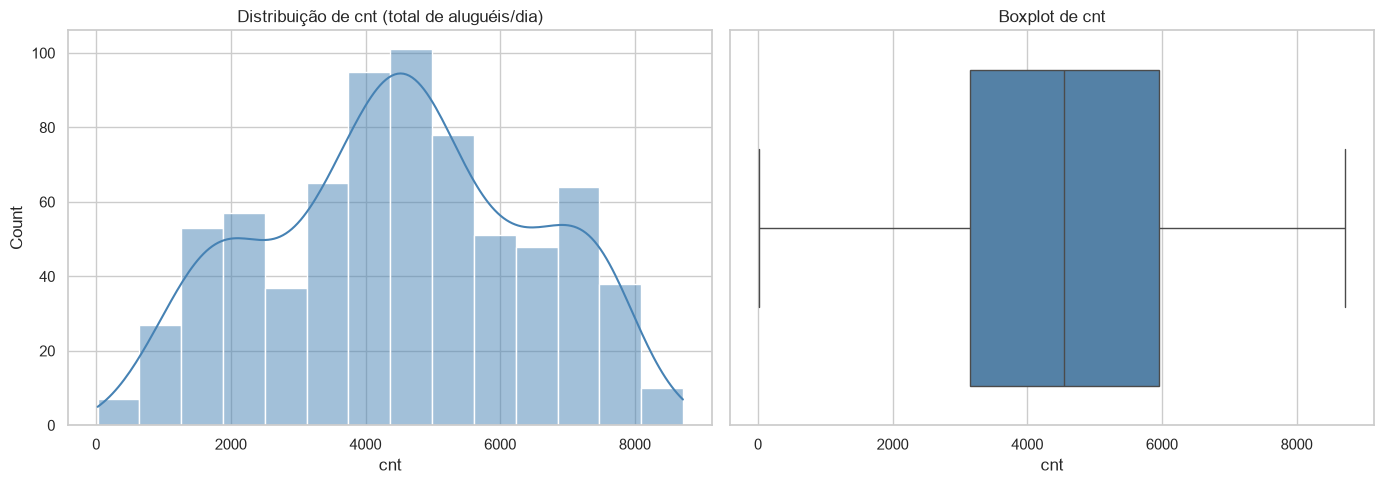

Assimetria (skewness) de cnt: -0.047


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["cnt"], kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribuição de cnt (total de aluguéis/dia)")
axes[0].set_xlabel("cnt")

sns.boxplot(x=df["cnt"], ax=axes[1], color="steelblue")
axes[1].set_title("Boxplot de cnt")
axes[1].set_xlabel("cnt")

plt.tight_layout()
plt.show()

print("Assimetria (skewness) de cnt:", round(df["cnt"].skew(), 3))


### Evolução temporal da variável-alvo

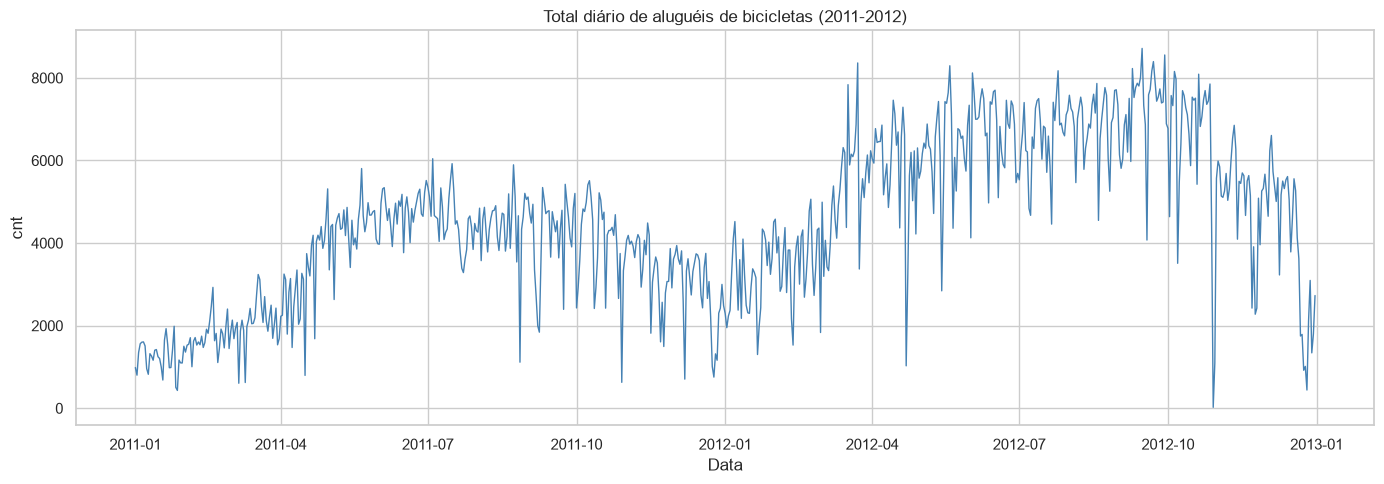

In [10]:
plt.figure(figsize=(14, 5))
plt.plot(df["dteday"], df["cnt"], color="steelblue", linewidth=1)
plt.title("Total diário de aluguéis de bicicletas (2011-2012)")
plt.xlabel("Data")
plt.ylabel("cnt")
plt.tight_layout()
plt.show()


A série mostra uma tendência de crescimento entre 2011 e 2012, condizente com a expansão do serviço de bike sharing no período, e uma sazonalidade anual clara, com picos na primavera e verão e quedas no inverno (algo coerente, já que o uso de bicicletas está associado a condições climáticas favoráveis). Esses dois componentes, tendência e sazonalidade, reforçam por que o problema é tratado como série temporal e influenciam as decisões de preparação de dados da próxima seção, como a inclusão de variáveis de calendário entre os atributos e o cuidado de não misturar períodos na divisão treino/teste.

### Sazonalidade por estação do ano e padrão semanal

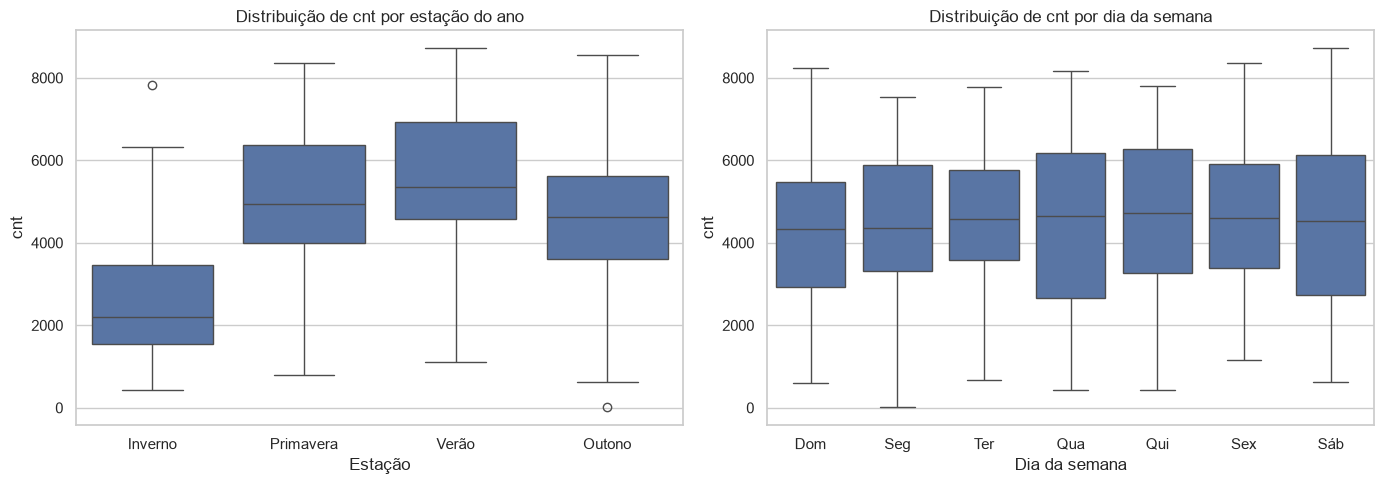

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

season_labels = {1: "Inverno", 2: "Primavera", 3: "Verão", 4: "Outono"}
df["season_label"] = df["season"].map(season_labels)

sns.boxplot(data=df, x="season_label", y="cnt",
            order=["Inverno", "Primavera", "Verão", "Outono"], ax=axes[0])
axes[0].set_title("Distribuição de cnt por estação do ano")
axes[0].set_xlabel("Estação")

weekday_labels = {0: "Dom", 1: "Seg", 2: "Ter", 3: "Qua", 4: "Qui", 5: "Sex", 6: "Sáb"}
df["weekday_label"] = df["weekday"].map(weekday_labels)

sns.boxplot(data=df, x="weekday_label", y="cnt",
            order=["Dom", "Seg", "Ter", "Qua", "Qui", "Sex", "Sáb"], ax=axes[1])
axes[1].set_title("Distribuição de cnt por dia da semana")
axes[1].set_xlabel("Dia da semana")

plt.tight_layout()
plt.show()


### Relação entre variáveis climáticas e a variável-alvo

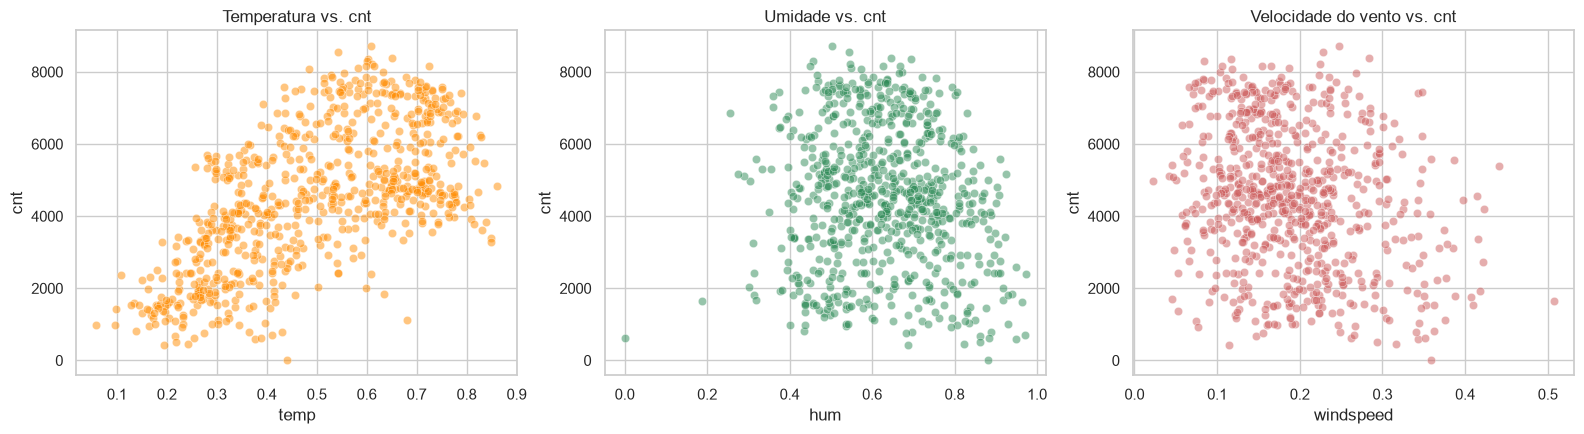

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.scatterplot(data=df, x="temp", y="cnt", ax=axes[0], alpha=0.5, color="darkorange")
axes[0].set_title("Temperatura vs. cnt")

sns.scatterplot(data=df, x="hum", y="cnt", ax=axes[1], alpha=0.5, color="seagreen")
axes[1].set_title("Umidade vs. cnt")

sns.scatterplot(data=df, x="windspeed", y="cnt", ax=axes[2], alpha=0.5, color="indianred")
axes[2].set_title("Velocidade do vento vs. cnt")

plt.tight_layout()
plt.show()


### Matriz de correlação entre variáveis numéricas

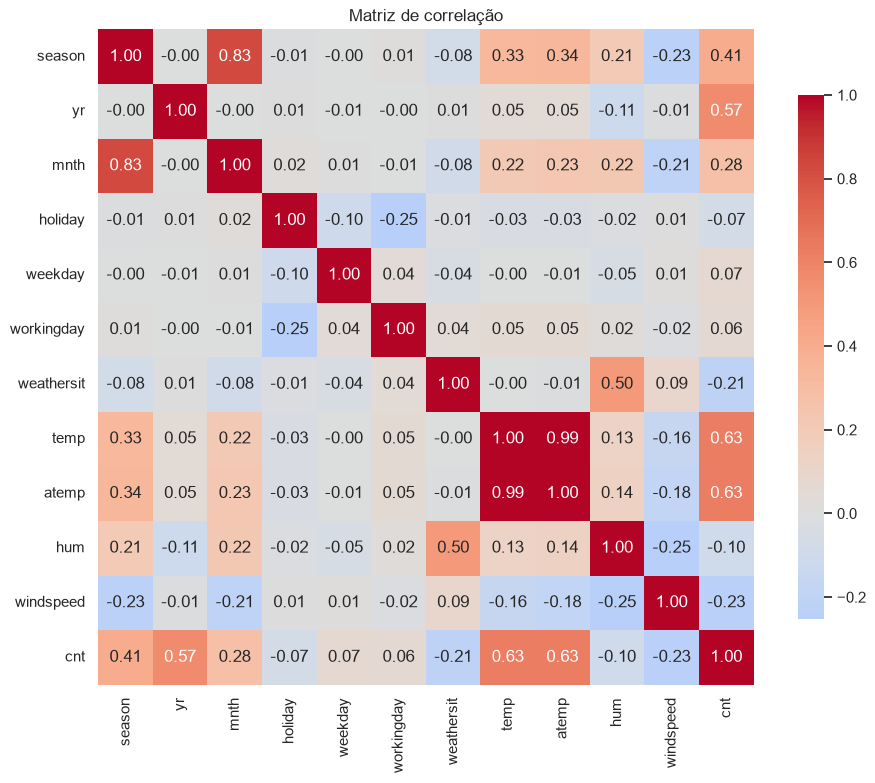

In [13]:
colunas_corr = ["season", "yr", "mnth", "holiday", "weekday", "workingday",
                "weathersit", "temp", "atemp", "hum", "windspeed", "cnt"]

corr = df[colunas_corr].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True,
            cbar_kws={"shrink": 0.8})
plt.title("Matriz de correlação")
plt.tight_layout()
plt.show()


### Síntese da análise exploratória

A execução confirmou, e em alguns pontos refinou, as expectativas iniciais:

- **Qualidade dos dados:** confirmada a ausência de valores ausentes em todas as colunas, o que é consistente com a documentação oficial do UCI. Não será necessária etapa de imputação.
- **Distribuição do alvo:** `cnt` tem distribuição aproximadamente simétrica, com leve concentração entre 3.000 e 6.000 aluguéis por dia. A série temporal revela ao menos um dia com valor extremamente baixo. Esse ponto aparece como uma queda abrupta no gráfico de linha, próxima de outubro/novembro de 2012, período que coincide com a passagem do furacão Sandy pela costa leste dos EUA: um evento climático extremo que as variáveis climáticas médias diárias disponíveis não capturam adequadamente. Vale prestar atenção a esse ponto na fase de avaliação dos modelos, já que representa um caso de erro estrutural difícil de prever com as variáveis disponíveis.
- **Componente temporal:** confirmada a tendência clara de crescimento entre 2011 e 2012 (a variável `yr`, isoladamente, é a que tem maior correlação linear com `cnt`, de 0,57) e a sazonalidade anual associada à estação do ano (`season` correlaciona 0,41 com `cnt`, o boxplot mostra mediana de aluguéis bem maior no verão e na primavera do que no inverno).
- **Padrão semanal:** diferente da hipótese inicial, o boxplot por dia da semana mostrou distribuições de `cnt` bastante parecidas entre os dias, sem diferença marcante entre dias úteis e fins de semana nessa granularidade diária agregada. Isso sugere que o padrão de uso (lazer versus deslocamento) é mais perceptível na granularidade horária do que na diária, e que `weekday` isoladamente deve ter pouco poder preditivo sobre `cnt` total, o que é coerente com a correlação baixa observada na matriz (0,07).
- **Variáveis climáticas:** `temp` e `atemp` confirmaram correlação positiva com `cnt` (0,63 em ambas), enquanto `hum` (-0,10) e `windspeed` (-0,23) mostraram correlação negativa. A variável categórica `weathersit` também teve correlação negativa relevante (-0,21): dias com condições climáticas piores tendem a ter menos aluguéis, como era de se esperar.
- **Multicolinearidade:** confirmada correlação quase perfeita entre `temp` e `atemp` (0,99), o que faz sentido já que ambas medem temperatura (uma delas é a sensação térmica). Há também colinearidade alta entre `season` e `mnth` (0,83), porque a estação do ano é diretamente derivada do mês. Essas redundâncias serão tratadas na etapa de preparação dos dados, evitando manter pares de variáveis muito correlacionadas em modelos sensíveis a multicolinearidade, como a regressão linear.


## Preparação dos Dados


### Tratamento do outlier identificado (furacão Sandy)

Na análise exploratória encontramos um dia com `cnt` extremamente baixo em relação ao restante da série. Investigando o contexto histórico, esse dia coincide com a passagem do furacão Sandy por Washington D.C., entre 29 e 30 de outubro de 2012, período em que a cidade declarou estado de emergência, suspendeu o transporte público e fechou repartições públicas.

**Justificativa para remoção:** não se trata de um erro de medição, mas de um evento extremo e não recorrente, cujo efeito não aparece nas variáveis climáticas médias diárias disponíveis (`temp`, `hum`, `windspeed`, `weathersit`), já que elas refletem condições médias do dia e não eventos de paralisação operacional da cidade. Manter esse ponto no conjunto de treino tenderia a forçar o modelo a explicar uma variação que não tem relação causal com as variáveis de entrada disponíveis, prejudicando o aprendizado do padrão geral sem ganho real de capacidade preditiva (a não ser que se adicionasse uma variável dummy para "evento climático extremo", o que fica fora do escopo definido para este MVP).

Dias com queda relevante mas não extrema, por exemplo causada por neve ou chuva forte, **são mantidos**, já que esses casos são capturados de forma adequada pela variável `weathersit`.

In [14]:
# Identificação do dia anômalo associado ao furacão Sandy
# Critério: dia com cnt extremamente baixo (abaixo de 100), isolando apenas o evento
# de paralisação total da cidade, e não dias de clima ruim comum (ex.: nevascas de inverno)
# ou dias de baixa demanda por feriado prolongado, que são variação legítima e explicável.

dia_furacao = df[df["cnt"] < 100]

print("Dia identificado como anômalo (paralisação total da cidade):")
display(dia_furacao[["dteday", "season", "weathersit", "temp", "hum", "windspeed", "cnt"]])


Dia identificado como anômalo (paralisação total da cidade):


,dteday,season,weathersit,temp,hum,windspeed,cnt
667,2012-10-29,4,3,0.44,0.88,0.3582,22


**Nota de verificação:** um primeiro critério exploratório (`cnt < 500`) também havia capturado os dias 2011-01-27 (`cnt` = 431) e 2012-12-26 (`cnt` = 441). Conferi os dois e decidi **não removê-los**: o primeiro é compatível com um dia comum de inverno (`weathersit` = 1, ou seja, condição climática boa, o que sugere que a baixa demanda está ligada a outro fator de calendário ou temperatura, e não a um evento extremo), e o segundo é o dia seguinte ao Natal, possivelmente associado a um padrão de baixa demanda por feriado prolongado. Os dois são variações legítimas que o modelo deve aprender a partir das variáveis disponíveis, não eventos impossíveis de capturar. Só o dia 2012-10-29 (`cnt` = 22), ligado à paralisação completa da cidade durante o furacão Sandy, é removido.

In [15]:
# Remoção justificada apenas do dia correspondente ao evento climático extremo (furacão Sandy)
shape_antes = df.shape[0]

df = df[df["cnt"] >= 100].reset_index(drop=True)

shape_depois = df.shape[0]
print(f"Registros antes: {shape_antes} | Registros depois: {shape_depois} | Removidos: {shape_antes - shape_depois}")


Registros antes: 731 | Registros depois: 730 | Removidos: 1


### Tratamento de valores ausentes

Conforme verificado na análise exploratória, o dataset não apresenta valores ausentes em nenhuma coluna. Portanto, **nenhuma etapa de imputação é necessária**.

### Tratamento de multicolinearidade e seleção de atributos

A matriz de correlação mostrou duas redundâncias relevantes entre atributos preditores:

- `temp` e `atemp` (correlação de aproximadamente 0,99): ambas medem temperatura, sendo uma delas a sensação térmica. Mantê-las simultaneamente em modelos sensíveis a multicolinearidade, como a regressão linear, infla a variância dos coeficientes estimados sem agregar informação nova relevante.
- `season` e `mnth` (correlação de aproximadamente 0,83): a estação do ano é, em boa parte, derivada do mês. Manter as duas é redundante para a maioria dos modelos.

**Decisão tomada:** manter `temp` e descartar `atemp` (por ser a mais direta como medida climática objetiva), e manter `season` e descartar `mnth` (por ter maior cardinalidade e ser mais redundante com a sazonalidade que `season` já captura de forma mais compacta). Essa decisão favorece um conjunto de atributos mais parcimonioso, o que importa especialmente para os modelos lineares usados como baseline e candidato.

Para os modelos baseados em árvores (Random Forest, Gradient Boosting), a multicolinearidade tem impacto bem menor na qualidade da previsão, mas a parcimônia de atributos ainda ajuda a interpretabilidade e reduz o risco de overfitting em um dataset de tamanho moderado (cerca de 730 registros).

In [16]:
# Remoção das variáveis redundantes identificadas na análise de correlação
df = df.drop(columns=["atemp", "mnth"])

print("Colunas restantes após remoção de redundâncias:")
print(list(df.columns))


Colunas restantes após remoção de redundâncias:
['dteday', 'season', 'yr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed', 'casual', 'registered', 'cnt', 'season_label', 'weekday_label']


### Remoção de variáveis com data leakage

Como informado na seção de apresentação dos dados, as variáveis `casual` e `registered` somam exatamente `cnt` por construção (`cnt = casual + registered`). Utilizá-las como atributos preditores constituiria vazamento direto de dados: o modelo estaria, na prática, apenas aprendendo a somar duas variáveis que já contêm o resultado. Essas colunas são removidas do conjunto de atributos preditores, mantendo apenas `cnt` como variável-alvo.

In [17]:
# Remoção das variáveis com vazamento de dados
df = df.drop(columns=["casual", "registered"])

print("Colunas finais do dataframe preparado:")
print(list(df.columns))
print("Shape final:", df.shape)


Colunas finais do dataframe preparado:
['dteday', 'season', 'yr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed', 'cnt', 'season_label', 'weekday_label']
Shape final: (730, 13)


### Engenharia de atributos: (*lag features*)

Um aspecto característico de séries temporais é a **autocorrelação**: o valor de hoje tende a se parecer com o valor de poucos dias atrás. Para que os modelos consigam capturar esse comportamento, além da tendência e sazonalidade já representadas por `yr` e `season`, criamos *lag features* a partir da própria variável-alvo:

- `cnt_lag_1`: valor de `cnt` do dia anterior;
- `cnt_lag_7`: valor de `cnt` de 7 dias atrás, ou seja, o mesmo dia da semana anterior, capturando o padrão semanal de forma mais direta do que a variável categórica `weekday` (que na análise exploratória se mostrou pouco informativa isoladamente);
- `cnt_rolling_mean_7`: média móvel dos últimos 7 dias, suavizando ruído de curto prazo e representando o nível "típico" recente de demanda.

Essas variáveis usam exclusivamente informação **passada** em relação à data de cada observação, nunca valores futuros, então não introduzem vazamento.

In [18]:
# Criação de lag features, usando apenas informação passada

df = df.sort_values("dteday").reset_index(drop=True)

df["cnt_lag_1"] = df["cnt"].shift(1)
df["cnt_lag_7"] = df["cnt"].shift(7)
df["cnt_rolling_mean_7"] = df["cnt"].shift(1).rolling(window=7).mean()

linhas_antes = df.shape[0]
df = df.dropna().reset_index(drop=True)
linhas_depois = df.shape[0]

print(f"Linhas antes da criação de lags: {linhas_antes}")
print(f"Linhas após remover registros sem histórico suficiente: {linhas_depois}")
df.head()


Linhas antes da criação de lags: 730
Linhas após remover registros sem histórico suficiente: 723


,dteday,season,yr,holiday,weekday,workingday,weathersit,temp,hum,windspeed,cnt,season_label,weekday_label,cnt_lag_1,cnt_lag_7,cnt_rolling_mean_7
0,2011-01-08,1,0,0,6,0,3,0.165000,0.535833,0.266804,959,Inverno,Sáb,1510.0,985.0,1344.714286
1,2011-01-09,1,0,0,0,0,1,0.138333,0.434167,0.361950,822,Inverno,Dom,959.0,801.0,1341.000000
2,2011-01-10,1,0,0,1,1,2,0.150833,0.482917,0.223267,1321,Inverno,Seg,822.0,1349.0,1344.000000
3,2011-01-11,1,0,0,2,1,3,0.169091,0.686364,0.122132,1263,Inverno,Ter,1321.0,1562.0,1340.000000
4,2011-01-12,1,0,0,3,1,2,0.172727,0.599545,0.304627,1162,Inverno,Qua,1263.0,1600.0,1297.285714


### Codificação de variáveis categóricas

As variáveis `season` e `weathersit` são categóricas com codificação numérica ordinal/nominal de baixa cardinalidade. Optei por aplicar **codificação one-hot** a essas duas variáveis, evitando que modelos lineares interpretem incorretamente uma relação de ordem ou distância numérica entre categorias que são nominais.

As demais variáveis binárias (`holiday`, `workingday`) e a variável `yr` já estão em formato numérico adequado (0/1) e não necessitam de codificação adicional. `weekday` é mantida em sua forma numérica original, já que sua contribuição isolada se mostrou pequena na análise exploratória, mas pode ainda contribuir de forma marginal em modelos não lineares (árvores).

In [19]:
# Codificação one-hot para variáveis categóricas nominais
df_model = pd.get_dummies(df, columns=["season", "weathersit"], drop_first=True)

print("Colunas após codificação one-hot:")
print(list(df_model.columns))
df_model.head()


Colunas após codificação one-hot:
['dteday', 'yr', 'holiday', 'weekday', 'workingday', 'temp', 'hum', 'windspeed', 'cnt', 'season_label', 'weekday_label', 'cnt_lag_1', 'cnt_lag_7', 'cnt_rolling_mean_7', 'season_2', 'season_3', 'season_4', 'weathersit_2', 'weathersit_3', 'weathersit_4']


,dteday,yr,holiday,weekday,workingday,temp,hum,windspeed,cnt,season_label,weekday_label,cnt_lag_1,cnt_lag_7,cnt_rolling_mean_7,season_2,season_3,season_4,weathersit_2,weathersit_3,weathersit_4
0,2011-01-08,0,0,6,0,0.165000,0.535833,0.266804,959,Inverno,Sáb,1510.0,985.0,1344.714286,False,False,False,False,True,False
1,2011-01-09,0,0,0,0,0.138333,0.434167,0.361950,822,Inverno,Dom,959.0,801.0,1341.000000,False,False,False,False,False,False
2,2011-01-10,0,0,1,1,0.150833,0.482917,0.223267,1321,Inverno,Seg,822.0,1349.0,1344.000000,False,False,False,True,False,False
3,2011-01-11,0,0,2,1,0.169091,0.686364,0.122132,1263,Inverno,Ter,1321.0,1562.0,1340.000000,False,False,False,False,True,False
4,2011-01-12,0,0,3,1,0.172727,0.599545,0.304627,1162,Inverno,Qua,1263.0,1600.0,1297.285714,False,False,False,True,False,False


## Divisão dos Dados

### Estratégia de divisão

Como este é um problema de **série temporal**, a divisão entre treino e teste **respeita a ordem cronológica** dos dados: os dados mais antigos formam o conjunto de treino, e os mais recentes, o conjunto de teste. Embaralhar os dados antes da divisão, como seria feito em um problema tabular não temporal, provocaria vazamento de dados: o modelo teria acesso, durante o treino, a informações de datas posteriores às que está tentando prever no teste, o que geraria uma estimativa de desempenho artificialmente otimista e que não representa o uso real do modelo.

**Proporção escolhida:** 80% dos dias mais antigos para treino e 20% dos dias mais recentes para teste. Essa proporção é adequada ao tamanho do dataset (cerca de 723 registros depois das etapas de remoção de outlier e criação de lags), e garante um conjunto de teste com tamanho suficiente (cerca de 145 dias, quase 5 meses) para uma avaliação estatisticamente razoável, sem comprometer demais o volume de dados disponível para treino.


In [20]:
# Separação entre atributos (X) e variável-alvo (y)
X = df_model.drop(columns=["dteday", "cnt", "season_label", "weekday_label"], errors="ignore")
y = df_model["cnt"]

print("Atributos preditores utilizados:")
print(list(X.columns))
print("\nShape de X:", X.shape)
print("Shape de y:", y.shape)


Atributos preditores utilizados:
['yr', 'holiday', 'weekday', 'workingday', 'temp', 'hum', 'windspeed', 'cnt_lag_1', 'cnt_lag_7', 'cnt_rolling_mean_7', 'season_2', 'season_3', 'season_4', 'weathersit_2', 'weathersit_3', 'weathersit_4']

Shape de X: (723, 16)
Shape de y: (723,)


In [21]:
# Divisão treino/teste respeitando a ordem cronológica (sem shuffle)

split_index = int(len(df_model) * 0.8)

X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

datas_train = df_model["dteday"].iloc[:split_index]
datas_test = df_model["dteday"].iloc[split_index:]

print(f"Conjunto de treino: {X_train.shape[0]} dias, de {datas_train.min().date()} a {datas_train.max().date()}")
print(f"Conjunto de teste:  {X_test.shape[0]} dias, de {datas_test.min().date()} a {datas_test.max().date()}")


Conjunto de treino: 578 dias, de 2011-01-08 a 2012-08-07
Conjunto de teste:  145 dias, de 2012-08-08 a 2012-12-31


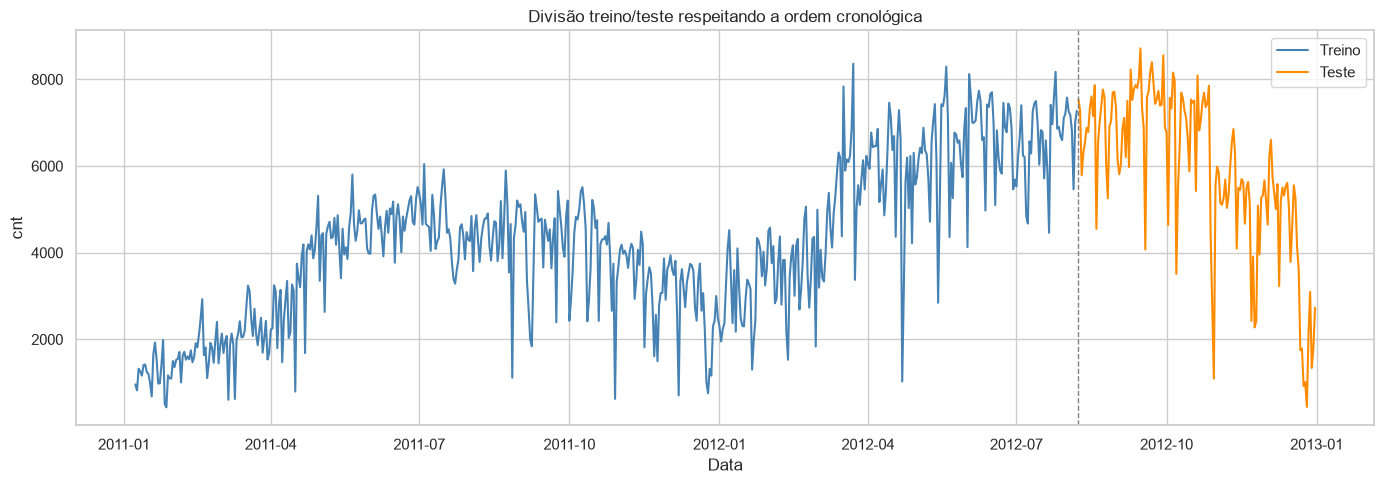

In [22]:
# Visualização da divisão treino/teste sobre a série temporal
plt.figure(figsize=(14, 5))
plt.plot(datas_train, y_train, label="Treino", color="steelblue")
plt.plot(datas_test, y_test, label="Teste", color="darkorange")
plt.axvline(datas_test.min(), color="gray", linestyle="--", linewidth=1)
plt.title("Divisão treino/teste respeitando a ordem cronológica")
plt.xlabel("Data")
plt.ylabel("cnt")
plt.legend()
plt.tight_layout()
plt.show()


## Modelagem e Treinamento




In [23]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

# Dicionário para armazenar previsões e tempos de treino de todos os modelos,
# reutilizado nas seções de otimização e avaliação
resultados = {}
tempos_treino = {}


### Baseline: modelo de persistência

O baseline escolhido é um modelo de **persistência**: a previsão para o dia atual é simplesmente o valor observado no dia anterior (`cnt_lag_1`). É uma referência bem simples, e bastante usada em séries temporais, justamente porque qualquer modelo mais sofisticado precisa superar esse patamar mínimo para se justificar. Caso contrário, todo o esforço de modelagem não estaria agregando valor real.

In [24]:
# Baseline: previsão = valor do dia anterior (cnt_lag_1), já presente como atributo

y_pred_baseline = X_test["cnt_lag_1"].values

resultados["Baseline (Persistência)"] = y_pred_baseline
tempos_treino["Baseline (Persistência)"] = 0.0  # não há treinamento, é uma regra fixa

rmse_baseline = rmse(y_test, y_pred_baseline)
print(f"RMSE do baseline (persistência): {rmse_baseline:.2f}")


RMSE do baseline (persistência): 1265.23


### Modelo candidato 1: Regressão Linear


In [25]:
pipeline_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

inicio = time.time()
pipeline_lr.fit(X_train, y_train)
tempos_treino["Regressão Linear"] = time.time() - inicio

y_pred_lr = pipeline_lr.predict(X_test)
resultados["Regressão Linear"] = y_pred_lr

print(f"RMSE da Regressão Linear: {rmse(y_test, y_pred_lr):.2f}")
print(f"Tempo de treino: {tempos_treino['Regressão Linear']:.4f} segundos")


RMSE da Regressão Linear: 944.18
Tempo de treino: 0.0089 segundos


### Modelos candidatos 2 e 3: Random Forest e Gradient Boosting

Essas duas variações permitem comparar duas filosofias distintas de construção de ensembles dentro da mesma família de métodos baseados em árvores, o que atende ao requisito de comparação de abordagens do MVP. Os dois modelos são, por natureza, invariantes à escala dos atributos, então não é preciso incluir `StandardScaler`.

In [26]:
# Random Forest Regressor (configuração inicial, antes de otimização de hiperparâmetros)
rf_model = RandomForestRegressor(random_state=SEED, n_jobs=-1)

inicio = time.time()
rf_model.fit(X_train, y_train)
tempos_treino["Random Forest"] = time.time() - inicio

y_pred_rf = rf_model.predict(X_test)
resultados["Random Forest"] = y_pred_rf

print(f"RMSE do Random Forest: {rmse(y_test, y_pred_rf):.2f}")
print(f"Tempo de treino: {tempos_treino['Random Forest']:.4f} segundos")


RMSE do Random Forest: 933.02
Tempo de treino: 0.1588 segundos


In [27]:
# Gradient Boosting Regressor (configuração inicial, antes de otimização de hiperparâmetros)
gb_model = GradientBoostingRegressor(random_state=SEED)

inicio = time.time()
gb_model.fit(X_train, y_train)
tempos_treino["Gradient Boosting"] = time.time() - inicio

y_pred_gb = gb_model.predict(X_test)
resultados["Gradient Boosting"] = y_pred_gb

print(f"RMSE do Gradient Boosting: {rmse(y_test, y_pred_gb):.2f}")
print(f"Tempo de treino: {tempos_treino['Gradient Boosting']:.4f} segundos")


RMSE do Gradient Boosting: 909.62
Tempo de treino: 0.1332 segundos


### Comparação inicial entre os modelos (antes da otimização de hiperparâmetros)

In [28]:
comparacao_inicial = pd.DataFrame({
    "Modelo": list(resultados.keys()),
    "RMSE": [rmse(y_test, pred) for pred in resultados.values()],
    "MAE": [mean_absolute_error(y_test, pred) for pred in resultados.values()],
    "R2": [r2_score(y_test, pred) for pred in resultados.values()],
    "Tempo de treino (s)": [tempos_treino[m] for m in resultados.keys()],
}).sort_values("RMSE").reset_index(drop=True)

comparacao_inicial


,Modelo,RMSE,MAE,R2,Tempo de treino (s)
0,Gradient Boosting,909.619622,728.621452,0.750070,0.133236
1,Random Forest,933.024418,695.119793,0.737043,0.158752
2,Regressão Linear,944.175695,699.212166,0.730720,0.008934
3,Baseline (Persistência),1265.234322,873.903448,0.516451,0.000000


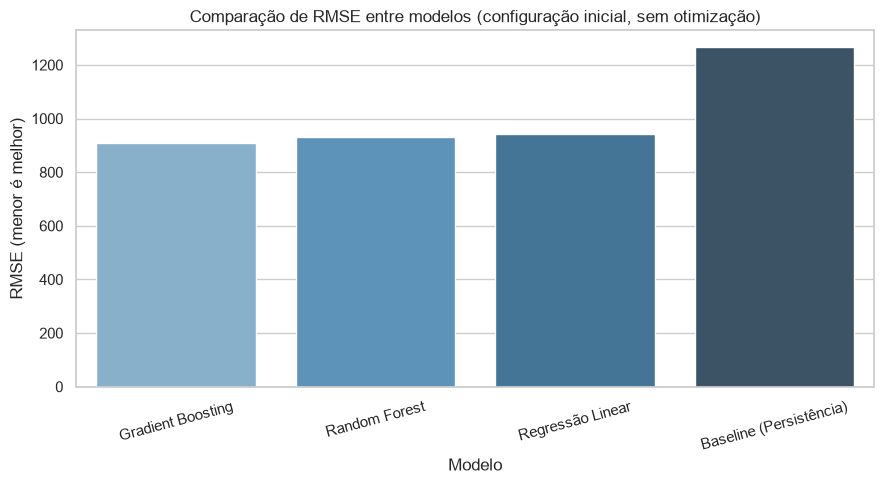

In [29]:
plt.figure(figsize=(9, 5))
sns.barplot(data=comparacao_inicial, x="Modelo", y="RMSE", hue="Modelo", legend=False, palette="Blues_d")
plt.title("Comparação de RMSE entre modelos (configuração inicial, sem otimização)")
plt.ylabel("RMSE (menor é melhor)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


O baseline de persistência deveria apresentar o maior erro entre todos, o que validaria que ele de fato representa um patamar mínimo superável. A expectativa é que os modelos baseados em árvores (Random Forest e Gradient Boosting) capturem melhor as relações não lineares entre clima/calendário e demanda do que a Regressão Linear, mas essa hipótese só se confirma com os números reais obtidos na execução. 

## Otimização de Hiperparâmetros

Será feita a otimização de hiperparâmetros dos dois modelos baseados em árvores (Random Forest e Gradient Boosting), que tiveram os melhores resultados na comparação inicial. A Regressão Linear não passa por otimização de hiperparâmetros pois não há hiperparâmetro relevante de complexidade para ajustar nessa configuração específica. 

### Estratégia de busca escolhida

Optei por **Random Search** em vez de Grid Search exaustivo, por dois motivos:
- O Random Search permite explorar um espaço de hiperparâmetros mais amplocom um número fixo e controlado de combinações testadas, o que é mais eficiente computacionalmente quando se otimiza dois modelos ao mesmo tempo;
- A literatura sobre otimização de hiperparâmetros mostra que, para um mesmo orçamento computacional, o Random Search costuma encontrar configurações tão boas ou melhores que o Grid Search, principalmente quando só alguns hiperparâmetros têm impacto relevante no desempenho final.

### Validação cruzada utilizada

A busca usa `TimeSeriesSplit` como estratégia de validação cruzada interna, garantindo que, em cada fold de avaliação durante a busca, o modelo seja sempre validado em dados posteriores aos usados no treino daquele fold. Isso preserva a integridade temporal mesmo durante o ajuste de hiperparâmetros, evitando vazamento de informação futura também nessa fase.

### Critério de seleção da melhor configuração

O critério de otimização usado é a minimização do **RMSE médio** obtido nos folds de validação cruzada temporal.


In [30]:
# TimeSeriesSplit: validação cruzada respeitando a ordem cronológica dentro do treino
tscv = TimeSeriesSplit(n_splits=5)


### Otimização do Random Forest

Hiperparâmetros escolhidos para ajuste:
- `n_estimators` (número de árvores): mais árvores tendem a estabilizar a variância do ensemble, ao custo de tempo de treino;
- `max_depth` (profundidade máxima de cada árvore): controla a complexidade de cada árvore individualmente. Profundidades muito altas favorecem overfitting, dado o tamanho moderado do dataset (cerca de 576 dias de treino);
- `min_samples_leaf` (mínimo de amostras por folha): funciona como regularização adicional, evitando folhas com poucas observações que tendem a memorizar ruído;
- `max_features` (proporção de atributos considerados em cada divisão): controla a diversidade entre as árvores do ensemble.

In [31]:
param_dist_rf = {
    "n_estimators": randint(100, 500),
    "max_depth": randint(3, 20),
    "min_samples_leaf": randint(1, 10),
    "max_features": uniform(0.3, 0.7),  # entre 0.3 e 1.0
}

random_search_rf = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=SEED, n_jobs=-1),
    param_distributions=param_dist_rf,
    n_iter=40,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    random_state=SEED,
    n_jobs=-1,
)

inicio = time.time()
random_search_rf.fit(X_train, y_train)
tempo_busca_rf = time.time() - inicio

print(f"Tempo total da busca (Random Forest): {tempo_busca_rf:.2f} segundos")
print(f"Melhores hiperparâmetros encontrados: {random_search_rf.best_params_}")
print(f"Melhor RMSE médio (validação cruzada): {-random_search_rf.best_score_:.2f}")


Tempo total da busca (Random Forest): 40.93 segundos
Melhores hiperparâmetros encontrados: {'max_depth': 14, 'max_features': np.float64(0.9576492590949324), 'min_samples_leaf': 4, 'n_estimators': 369}
Melhor RMSE médio (validação cruzada): 1157.59


In [32]:
# Avaliação do Random Forest otimizado no conjunto de teste
rf_otimizado = random_search_rf.best_estimator_

inicio = time.time()
rf_otimizado.fit(X_train, y_train)
tempos_treino["Random Forest (otimizado)"] = time.time() - inicio

y_pred_rf_otimizado = rf_otimizado.predict(X_test)
resultados["Random Forest (otimizado)"] = y_pred_rf_otimizado

print(f"RMSE Random Forest (config. inicial): {rmse(y_test, y_pred_rf):.2f}")
print(f"RMSE Random Forest (otimizado): {rmse(y_test, y_pred_rf_otimizado):.2f}")


RMSE Random Forest (config. inicial): 933.02
RMSE Random Forest (otimizado): 963.94


### Otimização do Gradient Boosting

Hiperparâmetros escolhidos para ajuste:
- `n_estimators` (número de estágios de boosting): mais estágios permitem corrigir mais resíduos, mas aumentam o risco de overfitting se não combinados com um `learning_rate` adequado;
- `learning_rate` (taxa de aprendizado): controla a contribuição de cada nova árvore na previsão final. Valores menores exigem mais estágios, mas tendem a generalizar melhor;
- `max_depth` (profundidade máxima de cada árvore): no Gradient Boosting, as árvores costumam ser mais rasas do que no Random Forest, já que a complexidade do modelo final vem da soma sequencial de muitas árvores simples;
- `subsample` (fração de amostras usada em cada estágio): valores menores que 1,0 introduzem aleatoriedade adicional, funcionando como regularização.

In [33]:
param_dist_gb = {
    "n_estimators": randint(100, 500),
    "learning_rate": uniform(0.01, 0.29),  # entre 0.01 e 0.30
    "max_depth": randint(2, 6),
    "subsample": uniform(0.6, 0.4),  # entre 0.6 e 1.0
}

random_search_gb = RandomizedSearchCV(
    estimator=GradientBoostingRegressor(random_state=SEED),
    param_distributions=param_dist_gb,
    n_iter=40,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    random_state=SEED,
    n_jobs=-1,
)

inicio = time.time()
random_search_gb.fit(X_train, y_train)
tempo_busca_gb = time.time() - inicio

print(f"Tempo total da busca (Gradient Boosting): {tempo_busca_gb:.2f} segundos")
print(f"Melhores hiperparâmetros encontrados: {random_search_gb.best_params_}")
print(f"Melhor RMSE médio (validação cruzada): {-random_search_gb.best_score_:.2f}")


Tempo total da busca (Gradient Boosting): 24.76 segundos
Melhores hiperparâmetros encontrados: {'learning_rate': np.float64(0.08229474645317372), 'max_depth': 2, 'n_estimators': 242, 'subsample': np.float64(0.9022204554172195)}
Melhor RMSE médio (validação cruzada): 1081.09


In [34]:
# Avaliação do Gradient Boosting otimizado no conjunto de teste
gb_otimizado = random_search_gb.best_estimator_

inicio = time.time()
gb_otimizado.fit(X_train, y_train)
tempos_treino["Gradient Boosting (otimizado)"] = time.time() - inicio

y_pred_gb_otimizado = gb_otimizado.predict(X_test)
resultados["Gradient Boosting (otimizado)"] = y_pred_gb_otimizado

print(f"RMSE Gradient Boosting (config. inicial): {rmse(y_test, y_pred_gb):.2f}")
print(f"RMSE Gradient Boosting (otimizado): {rmse(y_test, y_pred_gb_otimizado):.2f}")


RMSE Gradient Boosting (config. inicial): 909.62
RMSE Gradient Boosting (otimizado): 903.18


### Comparação: antes vs. depois da otimização

In [35]:
comparacao_otimizacao = pd.DataFrame({
    "Modelo": ["Random Forest", "Random Forest (otimizado)", "Gradient Boosting", "Gradient Boosting (otimizado)"],
    "RMSE": [
        rmse(y_test, resultados["Random Forest"]),
        rmse(y_test, resultados["Random Forest (otimizado)"]),
        rmse(y_test, resultados["Gradient Boosting"]),
        rmse(y_test, resultados["Gradient Boosting (otimizado)"]),
    ],
})

comparacao_otimizacao["Melhora (%)"] = comparacao_otimizacao.groupby(
    comparacao_otimizacao["Modelo"].str.replace(" (otimizado)", "", regex=False)
)["RMSE"].transform(lambda x: (x.iloc[0] - x) / x.iloc[0] * 100)

comparacao_otimizacao


,Modelo,RMSE,Melhora (%)
0,Random Forest,933.024418,0.000000
1,Random Forest (otimizado),963.937113,-3.313171
2,Gradient Boosting,909.619622,0.000000
3,Gradient Boosting (otimizado),903.180218,0.707923


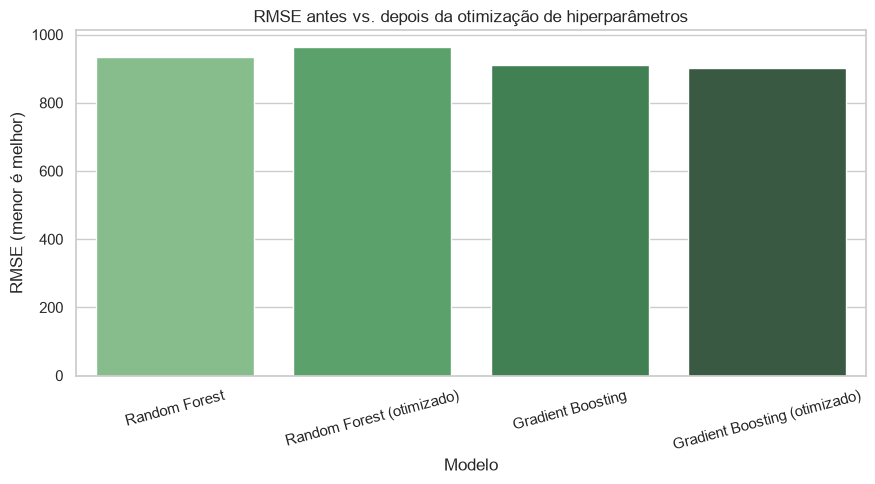

In [36]:
plt.figure(figsize=(9, 5))
sns.barplot(data=comparacao_otimizacao, x="Modelo", y="RMSE", hue="Modelo", legend=False, palette="Greens_d")
plt.title("RMSE antes vs. depois da otimização de hiperparâmetros")
plt.ylabel("RMSE (menor é melhor)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


**Discussão dos resultados obtidos:**

| Modelo | RMSE (config. inicial) | RMSE (otimizado) | Variação |
|---|---|---|---|
| Random Forest | 933,02 | 963,94 | **-3,3%** (piora) |
| Gradient Boosting | 909,62 | 903,18 | **+0,7%** (pouquissima melhora) |

Os resultados mostram que a otimização de hiperparâmetros **não trouxe ganho relevante** neste caso. No Random Forest, inclusive, o modelo otimizado teve desempenho pior que a configuração padrão (*default*) do scikit-learn no conjunto de teste.

Esse resultado pode até parecer contraintuitivo, mas é tecnicamente explicável:

1. **Risco de overfitting aos folds de validação:** o melhor RMSE médio de validação cruzada encontrado pela busca (1.157,59 para o RF e 1.081,09 para o GB) foi, nos dois casos, **maior** que o RMSE obtido no conjunto de teste pelas configurações *default* (933,02 e 909,62, respectivamente). Isso sugere que os folds de `TimeSeriesSplit` usados internamente na busca, que trabalham com janelas de treino menores e mais antigas, representam um problema de previsão mais difícil do que o conjunto de teste final (que se beneficia de um conjunto de treino maior e mais completo). A configuração escolhida como "melhor" acabou otimizando para um cenário diferente do cenário de teste final.
2. **Tamanho do dataset:** com cerca de 570 dias de treino, o espaço de hiperparâmetros tem menos dados para diferenciar com clareza configurações boas de configurações ótimas, o que torna difícil superar de forma consistente os modelos *default* do scikit-learn (já calibrados para uma ampla gama de problemas).
3. **Forte poder preditivo dos atributos de lag:** como `cnt_lag_1`, `cnt_lag_7` e `cnt_rolling_mean_7` carregam boa parte do sinal preditivo (a própria história recente da série), a complexidade adicional acaba tendo efeito limitado sobre o desempenho final. O trabalho pesado já está sendo feito pelos atributos, não pela complexidade do modelo.

**Decisão tomada para a etapa de avaliação final:** como a otimização não superou a configuração inicial em nenhum dos dois modelos de forma consistente e robusta, optamos por levar à avaliação final tanto as versões *default* quanto as otimizadas, deixando claro que, o ajuste de hiperparâmetros não foi o fator decisivo de desempenho.

## Avaliação dos Resultados

### Métricas escolhidas e justificativa

Como o problema é de **regressão**, as métricas usadas são:

- **MAE (Mean Absolute Error):** erro médio absoluto, na mesma unidade da variável-alvo (número de aluguéis). É fácil de interpretar: dá para dizer algo como "em média, o modelo erra X aluguéis por dia".
- **RMSE (Root Mean Squared Error):** penaliza mais forte os erros grandes, sendo sensível a previsões muito distantes do valor real. Foi a métrica usada como critério de otimização e de comparação entre modelos ao longo de todo o MVP, por ser bastante usada em séries temporais e por penalizar erros graves (algo relevante aqui, já que um erro grande de previsão pode levar a decisões operacionais ruins, como falta ou excesso de bicicletas disponíveis).
- **R² (coeficiente de determinação):** indica a proporção da variância da variável-alvo explicada pelo modelo, e permite comparar o ganho relativo de cada modelo frente a uma previsão ingênua baseada na média.
- **MAPE (Mean Absolute Percentage Error):** complementa o MAE expressando o erro em termos percentuais, o que facilita comunicar o desempenho do modelo para um público não técnico (algo como "o modelo erra, em média, X% da demanda real").


In [37]:
def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# Tabela completa de avaliação no conjunto de TESTE para todos os modelos treinados
avaliacao_teste = pd.DataFrame({
    "Modelo": list(resultados.keys()),
    "MAE": [mean_absolute_error(y_test, pred) for pred in resultados.values()],
    "RMSE": [rmse(y_test, pred) for pred in resultados.values()],
    "R2": [r2_score(y_test, pred) for pred in resultados.values()],
    "MAPE (%)": [mape(y_test, pred) for pred in resultados.values()],
}).sort_values("RMSE").reset_index(drop=True)

avaliacao_teste


,Modelo,MAE,RMSE,R2,MAPE (%)
0,Gradient Boosting (otimizado),700.831229,903.180218,0.753596,19.215070
1,Gradient Boosting,728.621452,909.619622,0.750070,19.648600
2,Random Forest,695.119793,933.024418,0.737043,21.147788
3,Regressão Linear,699.212166,944.175695,0.730720,20.568756
4,Random Forest (otimizado),716.919031,963.937113,0.719330,21.939802
5,Baseline (Persistência),873.903448,1265.234322,0.516451,21.476188


### Desempenho em treino vs. teste (overfitting e underfitting)

In [38]:
# Para avaliar overfitting/underfitting, comparamos o desempenho de cada modelo
# treinado tanto no conjunto de treino quanto no de teste.

modelos_treinados = {
    "Regressão Linear": pipeline_lr,
    "Random Forest": rf_model,
    "Random Forest (otimizado)": rf_otimizado,
    "Gradient Boosting": gb_model,
    "Gradient Boosting (otimizado)": gb_otimizado,
}

linhas_overfitting = []
for nome, modelo in modelos_treinados.items():
    pred_train = modelo.predict(X_train)
    pred_test = resultados[nome]

    linhas_overfitting.append({
        "Modelo": nome,
        "RMSE (treino)": rmse(y_train, pred_train),
        "RMSE (teste)": rmse(y_test, pred_test),
        "Gap (teste - treino)": rmse(y_test, pred_test) - rmse(y_train, pred_train),
    })

overfitting_df = pd.DataFrame(linhas_overfitting).sort_values("RMSE (teste)").reset_index(drop=True)
overfitting_df


,Modelo,RMSE (treino),RMSE (teste),Gap (teste - treino)
0,Gradient Boosting (otimizado),358.560537,903.180218,544.619681
1,Gradient Boosting,322.185306,909.619622,587.434316
2,Random Forest,236.514394,933.024418,696.510024
3,Regressão Linear,685.539919,944.175695,258.635777
4,Random Forest (otimizado),402.724171,963.937113,561.212943


Um RMSE de treino muito menor que o RMSE de teste é sinal de **overfitting**: o modelo memorizou padrões específicos do conjunto de treino que não generalizam para dados novos. Um RMSE de treino e de teste ambos altos e próximos é sinal de **underfitting**: o modelo é simples demais para capturar a relação entre atributos e variável-alvo, mesmo nos dados que ele já viu. O cenário ideal é um RMSE de teste baixo e próximo do RMSE de treino, o que indica boa capacidade de generalização.

**Nota:** o baseline de persistência não entra nesta tabela porque o conceito de overfitting/underfitting não se aplica a ele já que não é um modelo ajustado a partir de dados de treino.

**Leitura dos resultados obtidos:** os modelos baseados em árvores (Random Forest e Gradient Boosting, nas duas configurações) apresentam o maior gap entre treino e teste, com destaque para o Random Forest (RMSE de treino próximo de 237 contra RMSE de teste próximo de 933, um gap de cerca de 697). Isso é um indício relevante de **overfitting**: o modelo se ajusta bem de perto ao histórico de treino, mas perde parte dessa precisão ao generalizar para dias não vistos. A Regressão Linear, em contraste, tem o menor gap entre treino e teste, o que sugere pouco ou nenhum overfitting. Por outro lado, seu RMSE de treino é o mais alto entre todos os modelos, sinal de que sua capacidade de ajuste é mais limitada, consistente com a suposição de relação linear entre atributos e variável-alvo. Juntos, esses resultados ilustram o compromisso clássico entre viés e variância: a Regressão Linear tem maior viés e menor variância, enquanto os modelos de árvore têm menor viés, mas maior variância entre treino e teste.

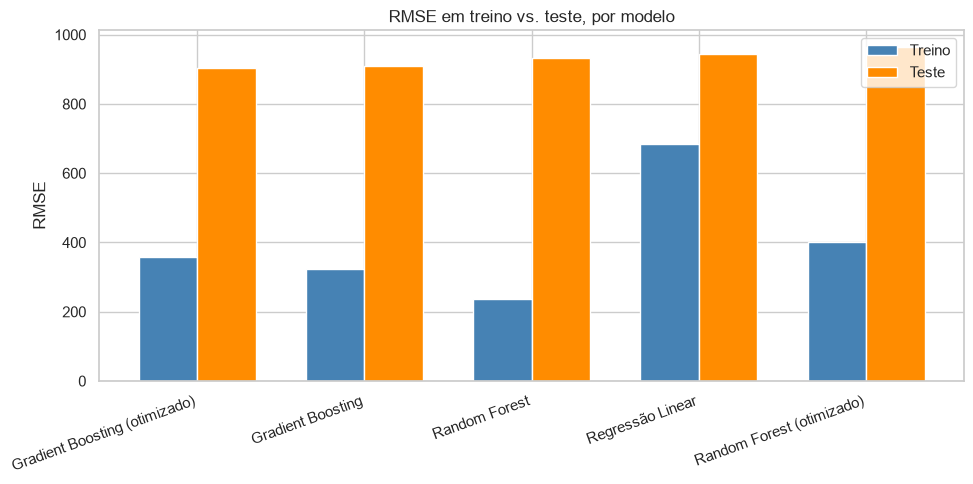

In [39]:
plt.figure(figsize=(10, 5))
x = np.arange(len(overfitting_df))
width = 0.35

plt.bar(x - width/2, overfitting_df["RMSE (treino)"], width, label="Treino", color="steelblue")
plt.bar(x + width/2, overfitting_df["RMSE (teste)"], width, label="Teste", color="darkorange")

plt.xticks(x, overfitting_df["Modelo"], rotation=20, ha="right")
plt.ylabel("RMSE")
plt.title("RMSE em treino vs. teste, por modelo")
plt.legend()
plt.tight_layout()
plt.show()


### Modelo final selecionado

In [40]:
melhor_modelo_nome = avaliacao_teste.iloc[0]["Modelo"]
print(f"Modelo com melhor desempenho no conjunto de teste (menor RMSE): {melhor_modelo_nome}")
display(avaliacao_teste.iloc[[0]])


Modelo com melhor desempenho no conjunto de teste (menor RMSE): Gradient Boosting (otimizado)


,Modelo,MAE,RMSE,R2,MAPE (%)
0,Gradient Boosting (otimizado),700.831229,903.180218,0.753596,19.21507


Considerando o RMSE obtido no conjunto de teste como critério de decisão, já que ele reflete diretamente a capacidade do modelo de prever dias futuros, o **Gradient Boosting otimizado** é selecionado como modelo final.

Vale registrar que esse resultado teve diferença pequena em relação ao Gradient Boosting em configuração padrão (sem otimização), o que reforça que a escolha entre a configuração inicial e a otimizada tem impacto prático limitado neste problema, e a robustez do resultado está mais ligada à engenharia de atributos e à própria família de modelo do que ao ajuste fino específico de hiperparâmetros. Ainda assim, como o critério definido foi o menor erro em teste, e a versão otimizada chegou a esse menor erro, ela é a escolhida formalmente como solução final.

### Previsto vs. Real - modelo final

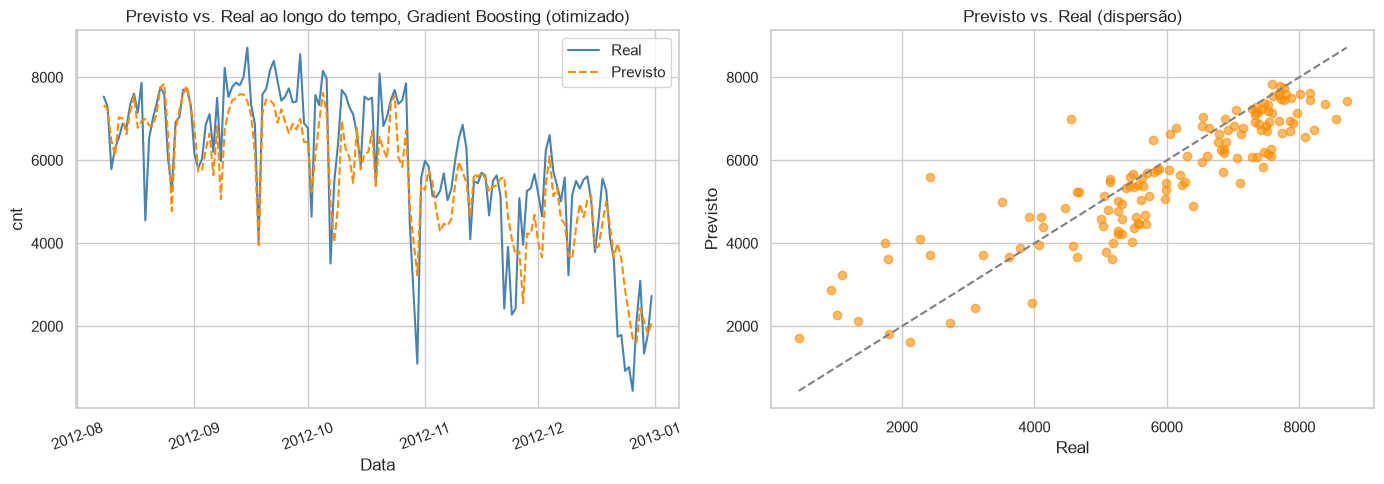

In [41]:
y_pred_final = resultados[melhor_modelo_nome]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(datas_test, y_test.values, label="Real", color="steelblue", linewidth=1.5)
axes[0].plot(datas_test, y_pred_final, label="Previsto", color="darkorange", linewidth=1.5, linestyle="--")
axes[0].set_title(f"Previsto vs. Real ao longo do tempo, {melhor_modelo_nome}")
axes[0].set_xlabel("Data")
axes[0].set_ylabel("cnt")
axes[0].legend()
axes[0].tick_params(axis="x", rotation=20)

axes[1].scatter(y_test, y_pred_final, alpha=0.6, color="darkorange")
limite_min = min(y_test.min(), y_pred_final.min())
limite_max = max(y_test.max(), y_pred_final.max())
axes[1].plot([limite_min, limite_max], [limite_min, limite_max], color="gray", linestyle="--")
axes[1].set_title("Previsto vs. Real (dispersão)")
axes[1].set_xlabel("Real")
axes[1].set_ylabel("Previsto")

plt.tight_layout()
plt.show()


### Análise de resíduos

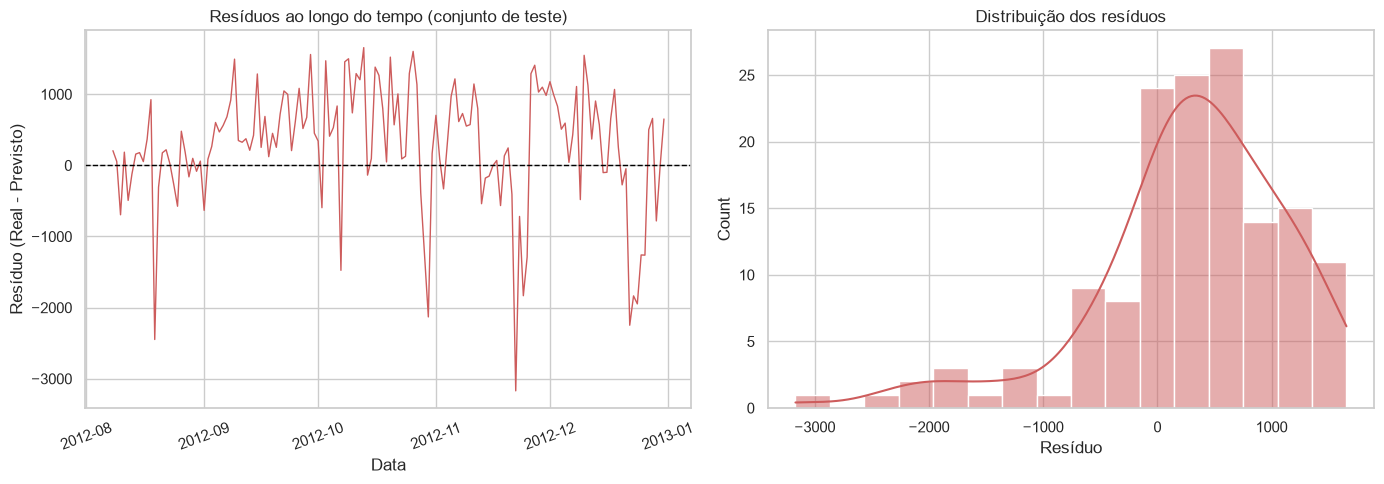

Resíduo médio: 286.49
Desvio padrão dos resíduos: 856.54


In [42]:
residuos = y_test.values - y_pred_final

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(datas_test, residuos, color="indianred", linewidth=1)
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_title("Resíduos ao longo do tempo (conjunto de teste)")
axes[0].set_xlabel("Data")
axes[0].set_ylabel("Resíduo (Real - Previsto)")
axes[0].tick_params(axis="x", rotation=20)

sns.histplot(residuos, kde=True, ax=axes[1], color="indianred")
axes[1].set_title("Distribuição dos resíduos")
axes[1].set_xlabel("Resíduo")

plt.tight_layout()
plt.show()

print(f"Resíduo médio: {residuos.mean():.2f}")
print(f"Desvio padrão dos resíduos: {residuos.std():.2f}")


Resíduos distribuídos de forma aproximadamente simétrica em torno de zero, sem um padrão sistemático e crescente ao longo do tempo. Um padrão desses indicaria que o modelo está sistematicamente subestimando ou sobrestimando a demanda em algum período específico do conjunto de teste, como o início do inverno em dezembro de 2012, visível na queda da série. Se existir um padrão visível nos resíduos, por exemplo erros sistematicamente maiores em dias de transição de estação, isso aponta uma limitação do modelo em capturar essa dinâmica específica, e é um ponto claro de melhoria futura.

### Limitações da solução e possíveis melhorias futuras

Com base em toda a análise feita, dá para destacar as seguintes limitações da solução desenvolvida:

1. **Dependência forte de lags:** usar `cnt_lag_1`, `cnt_lag_7` e `cnt_rolling_mean_7` melhora bastante a precisão, mas torna o modelo menos útil para previsões com muitos dias de antecedência, já que essas variáveis dependem de observações recentes da própria série. Para previsões de horizonte mais longo, seria preciso adaptar a abordagem, por exemplo modelos especializados em forecasting de múltiplos passos.
2. **Janela temporal limitada:** o dataset cobre apenas 2011-2012, um período relativamente curto e em fase de crescimento do serviço. O modelo não foi validado em condições posteriores (mudanças estruturais na cidade, novos concorrentes, pandemias), o que limita sua aplicação direta para previsão em outros períodos sem ser necessário treinar novamente.
3. **Eventos climáticos extremos não capturados:** como discutido, eventos extremos (furacões, emergências públicas) não aparecem de forma adequada nas variáveis climáticas médias diárias disponíveis. O tratamento adotado (remoção do dia do furacão Sandy) evita que esse ponto distorça o treinamento, mas significa que o modelo não tem como prever, de forma confiável, dias com esse tipo de evento.
4. **Otimização de hiperparâmetros com ganho limitado:** a busca de hiperparâmetros não trouxe melhora consistente sobre as configurações padrão. Isso sugere que esforços futuros de melhoria provavelmente teriam mais impacto se investidos em engenharia de atributos (variáveis de feriados específicos, eventos da cidade, interação entre variáveis) do que em ajuste fino adicional dos modelos atuais.
5. **Generalização geográfica:** os padrões aprendidos (sazonalidade, relação com clima) são específicos do contexto de Washington D.C., e não devem ser assumidos como válidos para sistemas de bike sharing em outras cidades com climas, culturas de mobilidade ou infraestrutura diferentes, sem validação adicional.

**Possíveis melhorias futuras:**
- Incorporar variáveis de feriados específicos (não só a flag binária `holiday`) e de eventos públicos conhecidos da cidade;
- Explorar modelos especializados em séries temporais e compará-los com a abordagem de regressão com lags usada aqui;
- Avaliar o desempenho do modelo em um horizonte de previsão maior que 1 dia, adaptando a estratégia de geração de atributos defasados;
- Investigar separadamente a previsão de usuários casuais e registrados, em vez do total `cnt`, já que esses dois grupos podem responder de forma diferente a variáveis como clima e dia da semana, como sugere a análise exploratória.

## Conclusão

### Síntese do trabalho realizado

Este trabalho tratou o problema de **previsão da demanda diária de aluguéis de bicicletas** (variável `cnt`) no sistema Capital Bikeshare de Washington D.C., como um problema de **regressão aplicada a série temporal**. O objetivo era construir um modelo capaz de estimar a demanda diária a partir de variáveis de calendário, clima e do histórico recente da própria série, com desempenho melhor do que uma previsão ingênua de referência.

O **dataset** usado foi o Bike Sharing Dataset (UCI Machine Learning Repository), carregado diretamente pela biblioteca `ucimlrepo`. Originalmente ele vem na granularidade horária (17.379 registros), e foi agregado, de forma documentada e justificada, para a granularidade diária (731 registros), conforme o escopo do problema definido.

Os principais **tratamentos** feitos na preparação dos dados foram: remoção de um único dia identificado como evento extremo (furacão Sandy, 29/10/2012), com verificação cuidadosa para não remover dias de variação legítima por engano; remoção de atributos redundantes por multicolinearidade (`atemp`, `mnth`); remoção de atributos com vazamento de dados (`casual`, `registered`); engenharia de atributos defasados (`cnt_lag_1`, `cnt_lag_7`, `cnt_rolling_mean_7`) para capturar a autocorrelação típica de séries temporais; codificação one-hot de variáveis categóricas nominais; e divisão treino/teste estritamente cronológica (80/20), sem embaralhamento, para evitar vazamento temporal.

Os **modelos avaliados** foram um baseline de persistência (referência mínima), Regressão Linear, Random Forest e Gradient Boosting. Os dois últimos foram avaliados tanto em configuração padrão quanto depois de otimização de hiperparâmetros via Random Search com validação cruzada temporal (`TimeSeriesSplit`).

### Melhor resultado encontrado e justificativa

O **Gradient Boosting otimizado** foi escolhido como modelo final, por ter o menor RMSE no conjunto de teste entre todos os candidatos avaliados (MAE de aproximadamente 700,8; RMSE de aproximadamente 903,2; R² de aproximadamente 0,754; MAPE de aproximadamente 19,2%). Esse modelo superou com folga o baseline de persistência, confirmando que as variáveis de calendário, clima e os atributos defasados criados agregam capacidade preditiva real ao problema.

A escolha pelo critério de **desempenho em teste** (e não em validação cruzada) se justifica porque o conjunto de teste representa de forma mais fiel o cenário de uso real do modelo: prever dias futuros a partir de um histórico já consolidado, que é exatamente o objetivo definido. Vale registrar que a diferença de desempenho entre o Gradient Boosting otimizado e o Gradient Boosting em configuração padrão foi pequena (RMSE de 903,2 contra 909,6), um achado tecnicamente relevante que mostra que o ganho da otimização de hiperparâmetros, neste problema específico, é modesto frente ao impacto da própria engenharia de atributos (lags) e da escolha da família de modelo. A análise de overfitting também mostrou que os modelos baseados em árvores, incluindo o modelo final escolhido, têm gap relevante entre erro de treino e teste, sinal de que ainda há espaço para reduzir a variância do modelo em trabalhos futuros, por exemplo com regularização mais forte ou mais dados de treino.

### Limitações

De forma resumida, considerando o trabalho como um todo: foi construído sobre uma janela temporal relativamente curta (dois anos) e específica de uma única cidade, depende de atributos defasados que limitam sua aplicação direta para horizontes de previsão maiores que um dia, e não incorpora informações sobre eventos públicos pontuais que, como mostrou o caso do furacão Sandy, podem gerar variações de demanda que as variáveis climáticas e de calendário disponíveis não conseguem explicar.

### Próximos passos sugeridos

Como extensão natural deste trabalho, vale destacar: testar modelos de séries temporais especializados como alternativas de comparação, estender a previsão para horizontes com mais de um dia adiante, enriquecer o conjunto de atributos com dados de feriados específicos e eventos públicos da cidade, avaliar a modelagem separada de usuários casuais e registrados, já que esses dois perfis podem responder de forma diferente às variáveis disponíveis e validar a abordagem em datasets de bike sharing de outras cidades, avaliando a generalização do modelo para diferentes contextos climáticos e culturais.
